# TP2 - Ejercicios 2 y 3: Aprendizaje por refuerzo

Q-Learning tabular y DQN con NumPy, Gymnasium y PyTorch.

## 1. Taxi-v3: definición del MDP; Navegación urbana

Modelamos la navegación autónoma del agente a través del tráfico cruzado. 

* El estado codifica fila, columna, posición del pasajero y destino (25×5×4 = 500 estados). 

* Las seis acciones son cuatro movimientos cardinales, subir y bajar al cliente. 

* El modelo de transición es determinista dado estado y acción con los valores por defecto y los estados iniciales se sortean. 

* La recompensa base es −1 por paso, −10 por recogida o descenso ilegal y +20 por entrega correcta. γ=0,97 balancea la urgencia de entrega con la exploración.

In [1]:
import os
import time
import math
import json
import random
from collections import deque
from pathlib import Path
from IPython.display import Image, Video, display
import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn

ROOT = Path.cwd()
PROFILE = os.getenv("TP2_PROFILE", "full")
SMOKE = PROFILE == "smoke"
OUT = ROOT / "resultados" / PROFILE
OUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(min(2, os.cpu_count() or 1))
MAX_DQN_EPISODES = 700

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def save_json(name, result):
    (OUT / (name + ".json")).write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")

def save_checkpoint(path, obj):
    temporary = path.with_suffix(".tmp")
    torch.save(obj, temporary)
    temporary.replace(path)

def rolling(values, window):
    values = np.asarray(values, dtype=float)
    cumsum = np.cumsum(np.insert(values, 0, 0))
    return (cumsum[window:] - cumsum[:-window]) / window

def first_cross(history, threshold, window=50):
    if len(history) < window:
        return None
    means = rolling(history, window)
    hits = np.flatnonzero(means >= threshold)
    return int(hits[0] + window) if len(hits) else None

def smooth(values, weight=0.9):
    smoothed, running = [], 0.0
    for value in values:
        running = value if not smoothed else weight * running + (1 - weight) * value
        smoothed.append(running)
    return smoothed

def save_figure(fig, name, show=False):
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", dpi=145)
    if show:
        plt.show()
    plt.close(fig)

def obtener_resultado(nombre, ejecutar):
    ruta = OUT / (nombre + ".json")
    return json.loads(ruta.read_text(encoding="utf-8")) if ruta.is_file() else ejecutar()

seed_everything(42)
taxi_env = gym.make("Taxi-v3")
print(taxi_env.observation_space, taxi_env.action_space)
print("Entradas:", taxi_env.observation_space.n * taxi_env.action_space.n)
taxi_env.close()


Discrete(500) Discrete(6)
Entradas: 3000


La tabla contiene 3.000 posiciones posibles, aunque no todas las combinaciones son alcanzables en la misma fase del episodio.

## 2. Q-Learning y recompensa

* El agente aprende a esquivar las barreras urbanas y el tráfico cruzado. 
* Aplicamos epsilon-greedy con decaimiento exponencial y actualización de Bellman. 
* Comparamos la recompensa original con distancia Manhattan y con un bono de pick up más penalización adicional por acción ilegal. 

- La comparación externa siempre mide el retorno original y éxito de entrega.

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (550, 350) to (560, 352) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


,media_original_100,media_moldeada_100,episodio_90
original,6.34,6.340,2023.0
distancia,6.39,14.895,1998.0
pick up,-210.08,160.200,NaN


Ciclo de la política con bono de recogida, semilla 0


,estado,accion,original,moldeado
0,474,recoger,-1,3.0
1,478,dejar,-1,-1.0
2,474,recoger,-1,3.0
3,478,dejar,-1,-1.0


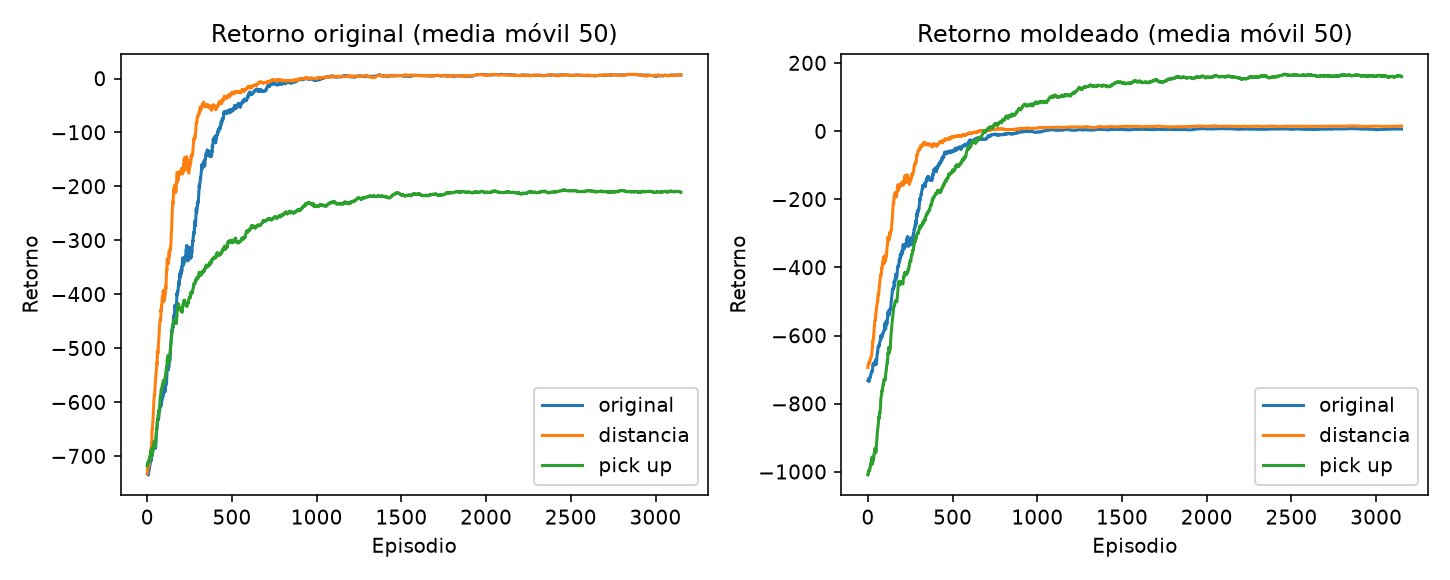

In [2]:
def taxi_potential(state):
    taxi_row, taxi_col, passenger_idx, dest_idx = taxi_env.unwrapped.decode(state)
    coords = [(0, 0), (0, 4), (4, 0), (4, 3)]
    target = coords[dest_idx] if passenger_idx == 4 else coords[passenger_idx]
    dist = abs(taxi_row - target[0]) + abs(taxi_col - target[1])
    return -float(dist) - (3.0 if passenger_idx != 4 else 0.0)

def taxi_reward(kind, r, state, next_state):
    if kind == "distancia":
        done_target = state in (
            taxi_env.unwrapped.encode(r, c, 4, d)
            for d, (r, c) in enumerate([(0, 0), (0, 4), (4, 0), (4, 3)])
        )
        phi_next = 0.0 if done_target else taxi_potential(next_state)
        return r + 0.97 * phi_next - taxi_potential(state)
    if kind == "pick up":
        if r == -10:
            return -15.0
        taxi_row, taxi_col, passenger_idx, _ = taxi_env.unwrapped.decode(state)
        coords = [(0, 0), (0, 4), (4, 0), (4, 3)]
        if passenger_idx < 4 and (taxi_row, taxi_col) == coords[passenger_idx]:
            _, _, p_after, _ = taxi_env.unwrapped.decode(next_state)
            if p_after == 4:
                return r + 4.0
    return float(r)

def train_taxi(kind="original", episodes=3200, gamma=0.97, alpha=0.18):
    env = gym.make("Taxi-v3")
    q = np.zeros((env.observation_space.n, env.action_space.n), dtype=float)
    history_orig, history_shaped = [], []
    checkpoint = OUT / f"taxi_{kind}.npy"
    if checkpoint.exists():
        q = np.load(checkpoint)
        saved = OUT / "taxi.json"
        if saved.exists():
            payload = json.loads(saved.read_text(encoding="utf-8"))
            if kind in payload:
                env.close()
                return q, payload[kind]
    seed_everything(42)
    for ep in range(episodes):
        state, _ = env.reset(seed=42 + ep)
        epsilon = 0.03 + 0.97 * math.exp(-ep / 420.0)
        done, tot_orig, tot_shaped = False, 0.0, 0.0
        while not done:
            if random.random() < epsilon:
                action = env.action_space.sample()
            else:
                vals = q[state]
                ties = np.flatnonzero(vals == vals.max())
                action = int(np.random.choice(ties))
            next_state, r_orig, term, trunc, _ = env.step(action)
            r_used = taxi_reward(kind, r_orig, state, next_state)
            target = r_used if term else r_used + gamma * q[next_state].max()
            q[state, action] += alpha * (target - q[state, action])
            state = next_state
            tot_orig += r_orig
            tot_shaped += r_used
            done = term or trunc
        history_orig.append(tot_orig)
        history_shaped.append(tot_shaped)
    env.close()
    np.save(checkpoint, q)
    return q, {
        "retorno_original": history_orig,
        "retorno_moldeado": history_shaped,
        "media_original_100": float(np.mean(history_orig[-100:])),
        "media_moldeada_100": float(np.mean(history_shaped[-100:])),
        "episodio_90": first_cross([r > 0 for r in history_orig], 0.9, 100),
    }

def taxi_evaluate(q_table, episodes=100):
    env = gym.make("Taxi-v3")
    returns, successes = [], []
    for ep in range(episodes):
        state, _ = env.reset(seed=1000 + ep)
        done, total = False, 0.0
        while not done:
            action = int(np.argmax(q_table[state]))
            state, reward, term, trunc, _ = env.step(action)
            total += reward
            done = term or trunc
        returns.append(total)
        successes.append(float(reward == 20))
    env.close()
    return float(np.mean(returns)), float(np.mean(successes))

def taxi_pickup_audit(q_table):
    env = gym.make("Taxi-v3")
    for seed in range(200):
        state, _ = env.reset(seed=seed)
        seen = {}
        for step in range(25):
            action = int(np.argmax(q_table[state]))
            seen[state] = step
            next_state, r_orig, term, trunc, _ = env.step(action)
            r_mold = taxi_reward("pick up", r_orig, state, next_state)
            if next_state in seen:
                cycle = []
                st = next_state
                for _ in range(6):
                    act = int(np.argmax(q_table[st]))
                    nxt, ro, tm, tr, _ = env.step(act)
                    cycle.append({
                        "estado": int(st),
                        "accion": ["sur", "norte", "este", "oeste", "recoger", "dejar"][act],
                        "original": int(ro),
                        "moldeado": float(taxi_reward("pick up", ro, st, nxt)),
                    })
                    st = nxt
                    if tm or tr:
                        break
                env.close()
                return {"semilla": seed, "ciclo": cycle[:4]}
            state = next_state
            if term or trunc:
                break
    env.close()
    return None

def record_episode(env_id, policy_fn, path):
    env = gym.make(env_id, render_mode="rgb_array")
    state, _ = env.reset(seed=42)
    frames, done, total = [], False, 0.0
    while not done:
        frames.append(env.render())
        action = policy_fn(state)
        state, reward, term, trunc, _ = env.step(action)
        total += reward
        done = term or trunc
    frames.append(env.render())
    env.close()
    if path.suffix == ".mp4":
        import imageio
        fps = 30 if "Lunar" in env_id else 5
        imageio.mimwrite(path, frames, fps=fps, codec="libx264", quality=8)
    elif path.suffix == ".png":
        plt.imsave(path, frames[-1])
    return total, len(frames)

def run_taxi(show=False, reuse=True):
    cache = OUT / "taxi.json"
    if reuse and cache.exists():
        data = json.loads(cache.read_text(encoding="utf-8"))
        tables = {kind: np.load(OUT / f"taxi_{kind}.npy") for kind in ("original", "distancia", "pick up")}
    else:
        episodes = 200 if SMOKE else 3200
        data, tables = {}, {}
        for kind in ("original", "distancia", "pick up"):
            q, stats = train_taxi(kind, episodes)
            data[kind], tables[kind] = stats, q
        data["pick up"]["auditoria"] = taxi_pickup_audit(tables["pick up"])
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        for kind, color in (("original", "tab:blue"), ("distancia", "tab:orange"), ("pick up", "tab:green")):
            axes[0].plot(rolling(data[kind]["retorno_original"], 50), label=kind, color=color)
            axes[1].plot(rolling(data[kind]["retorno_moldeado"], 50), label=kind, color=color)
        axes[0].set(xlabel="Episodio", ylabel="Retorno", title="Retorno original (media móvil 50)")
        axes[1].set(xlabel="Episodio", ylabel="Retorno", title="Retorno moldeado (media móvil 50)")
        for ax in axes:
            ax.legend()
        save_figure(fig, "taxi_curvas", show)
        ret, steps = record_episode("Taxi-v3", lambda s: int(np.argmax(tables["original"][s])), OUT / "taxi_episodio.mp4")
        record_episode("Taxi-v3", lambda s: int(np.argmax(tables["original"][s])), OUT / "taxi_episodio_final.png")
        data["demo"] = {"retorno": ret, "pasos": steps}
        save_json("taxi", data)
    return data

taxi = run_taxi(reuse=True)
display(pd.DataFrame({k: {x: y for x, y in v.items() if not isinstance(y, (list, dict))}
                      for k, v in taxi.items() if k != "demo"}).T)
auditoria = taxi["pick up"].get("auditoria")
if auditoria:
    print("Ciclo de la política con bono de recogida, semilla", auditoria["semilla"])
    display(pd.DataFrame(auditoria["ciclo"]))
display(Image(filename=str(OUT / "taxi_curvas.png")))
display(Video(filename=str(OUT / "taxi_episodio.mp4"), embed=True))


* El primer cruce del 90 % se mide en una ventana de 100 episodios completos. 

El video ilustra la conducta de la política greedy llevando a 'Emily' a su parada de destino por la ruta óptima. En cambio, con la recompensa modificada por bono aparece un ciclo cerrado donde el agente crea su propio atajo: el taxi sube y baja constantemente a 'Maxwell Edison' en la misma casilla para cobrar el incentivo sin entregar; la auditoría contrasta el retorno modificado y original de cada paso.

Primer 90 %: original: 390; distancia: 171; pick-up: no alcanzado.